In [ ]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import os

plt.style.use("default")

plt.rcParams.update(
    {
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial"],
        "font.size": 6,
        "axes.titlesize": 7,
        "axes.labelsize": 6,
        "axes.linewidth": 0.8,
        "xtick.labelsize": 6,
        "ytick.labelsize": 6,
        "xtick.major.size": 3,
        "ytick.major.size": 3,
        "xtick.major.width": 0.8,
        "ytick.major.width": 0.8,
        "legend.fontsize": 6,
        "legend.frameon": False,
        "lines.linewidth": 1.2,
        "lines.markersize": 4,
        "figure.figsize": (3.5, 2.6),
        "figure.dpi": 300,
        "savefig.dpi": 300,
        "savefig.bbox": "standard",
        # "savefig.pad_inches": 0.02,
        "pdf.fonttype": 42,
        "ps.fonttype": 42,
        "mathtext.fontset": "dejavusans",
    }
)
cm = 1 / 2.54  # centimeters in inches

results_path = "trafficking_inference/method_testing_unobserved/results/results_0909/"
figure_path = "trafficking_inference/method_testing_unobserved/figures/results_0909/"
# if the results_path does not exist, create it


if not os.path.exists(figure_path):
    os.makedirs(figure_path)

method_names = [
    "StitchOT with U",
    "JointOT with U",
    "StitchOT w/o U",
    "JointOT w/o U",
    "StitchOT w/o U \n and unsampled probs.",
    "JointOT w/o U \n and unsampled probs.",
    "StitchOT w/o U \n and random unsampled probs.",
    "JointOT w/o U \n and random unsampled probs.",
]

stats_names = [
    "TV distance [Sampled Comp.]",
    "TV distance [Unsampled Comp.]",
    r"Full $\overline{\text{ACC}^{\text{R}}_{\psi}}$",
    "Full IAE",
    "Conditional TV distance",
    r"Conditional $\overline{\text{ACC}^{\text{R}}_{\psi}}$",
    "Conditional IAE",
]

hue_names = ["StitchOT", "JointOT"] * 4


# set colors, I need two colormaps (blue, orange) alternating
colors_blue = sns.color_palette("Blues", n_colors=4)
colors_orange = sns.color_palette("Oranges", n_colors=4)
colors = []
colors_3 = ["#E64B35FF", "#4DBBD5FF", "#b3b3b3"]
for i in range(4):
    colors.append(colors_blue[i])
    colors.append(colors_orange[i])

results = np.zeros((200000, 8, 12))
real_fractions = np.zeros((200000, 5))
for job_id in range(2000):
    try:
        results[job_id * 100 : (job_id + 1) * 100, :, :] = np.load(
            f"{results_path}/results_{job_id}.npy"
        )
        # index 1 should be rescaled by 2
        results[job_id * 100 : (job_id + 1) * 100, :, 1] *= 2
        real_fractions[job_id * 100 : (job_id + 1) * 100, :] = np.load(
            f"{results_path}/real_fractions_{job_id}.npy"
        )
    except FileNotFoundError:
        print(f"File results_{job_id}.npy not found. Skipping this job.")
        continue


# The first dimension of the results array is basically flattened in a way such that this grid:
grid_U_base_rate_multiplier = np.linspace(
    0,
    1.0,
    20,
)
# flip the order of the grid so that it goes from 1.0 to 0
grid_U_base_rate_multiplier = grid_U_base_rate_multiplier[::-1]
grid_U_steepness = np.logspace(
    -3,
    0,
    10,
)

# is looped in
# for U_base_rate_multiplier in grid_U_base_rate_multiplier:
#    for U_steepness in grid_U_steepness:
# Do same 1000 parameter sets for each combination of U_base_rate_multiplier and U_steepness

# Redo flattening do get results for each point in the grid

# Reshape results to match the grid dimensions
results_grid = results.reshape(
    len(grid_U_base_rate_multiplier),
    len(grid_U_steepness),
    1000,  # 1000 parameter sets per grid point
    results.shape[1],  # 8 methods
    results.shape[2],  # 12 stats
)
real_fractions_grid = real_fractions.reshape(
    len(grid_U_base_rate_multiplier),
    len(grid_U_steepness),
    1000,  # 1000 parameter sets per grid point
    real_fractions.shape[1],  # 5 real fractions
)
# delete all rows where any of the real fractions are less than 100


results = results[~np.any(real_fractions < 25, axis=1)]
real_fractions = real_fractions[~np.any(real_fractions < 25, axis=1)]
print(
    f"Number of rows left after removing real fractions < 100: {real_fractions.shape[0]}"
)
# delete all rows that only contain zeros
real_fractions = real_fractions[~np.all(results == 0, axis=(1, 2))]
results = results[~np.all(results == 0, axis=(1, 2))]
# how many rows are left
print(f"Number of rows left: {results.shape[0]}")
# delete rows containing nans
real_fractions = real_fractions[~np.any(np.isnan(results), axis=(1, 2))]
results = results[~np.any(np.isnan(results), axis=(1, 2))]
print(f"Number of rows left after removing nans: {results.shape[0]}")

# create df_plot

File results_0.npy not found. Skipping this job.
File results_1.npy not found. Skipping this job.
File results_2.npy not found. Skipping this job.
File results_3.npy not found. Skipping this job.
File results_4.npy not found. Skipping this job.
File results_5.npy not found. Skipping this job.
File results_6.npy not found. Skipping this job.
File results_7.npy not found. Skipping this job.
File results_8.npy not found. Skipping this job.
File results_9.npy not found. Skipping this job.
File results_10.npy not found. Skipping this job.
File results_11.npy not found. Skipping this job.
File results_12.npy not found. Skipping this job.
File results_13.npy not found. Skipping this job.
File results_14.npy not found. Skipping this job.
File results_15.npy not found. Skipping this job.
File results_16.npy not found. Skipping this job.
File results_17.npy not found. Skipping this job.
File results_18.npy not found. Skipping this job.
File results_19.npy not found. Skipping this job.
File resul

In [2]:
for i, metric in enumerate(stats_names):
    plt.figure(figsize=((9, 4.2, "cm")), layout="constrained")
    # convert to dataframe so hue can be used
    df_plot = pd.DataFrame(results[:, :, i], columns=method_names)
    df_plot = df_plot.melt(var_name="Method", value_name=metric)
    # merge every two methods of method_names into one, so that the x-axis has 4 methods instead of 8

    # add second grouping by hue, which is StitchOT vs JointOT
    # if method contains Stitch then hue is StitchOT, else JointOT
    df_plot["Hue"] = df_plot["Method"].apply(
        lambda x: "StitchOT" if "Stitch" in x else "JointOT"
    )
    df_plot["Method"] = df_plot["Method"].replace(
        {
            "StitchOT with U": "with U",
            "JointOT with U": "with U",
            "StitchOT w/o U": "w/o U",
            "JointOT w/o U": "w/o U",
            "StitchOT w/o U \n and unsampled probs.": "unsampled probs.",
            "JointOT w/o U \n and unsampled probs.": "unsampled probs.",
            "StitchOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
            "JointOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
        }
    )
    sns.violinplot(
        data=df_plot,
        x="Method",
        y=metric,
        hue="Hue",
        palette=colors_3[:2],
        split=False,
        inner="quart",
        cut=0,
        gap=0.05,
    )
    # annotate the boxplots with the method names
    # plt.xticks(ticks=np.arange(4), labels=["with X", "w/o X", "w/o X and \n unsampled probs.", "w/o X and \n random unsampled probs."], rotation=90)
    # add horizontal grid lines
    plt.ylim(-0.02, None)
    plt.xlabel("")
    plt.yticks(ticks=np.arange(0, 1.1, 0.2))
    plt.grid(axis="y", linestyle="solid", alpha=0.4)
    plt.gca().set_axisbelow(True)
    plt.ylabel(stats_names[i])
    plt.savefig(f"{figure_path}{stats_names[i].replace(' ', '_')}_all_methods.pdf")
    plt.close()

### Do boxplots for max steepness grid points only

Number of rows left after removing real fractions < 50: 0


ValueError: x and y must be the same size

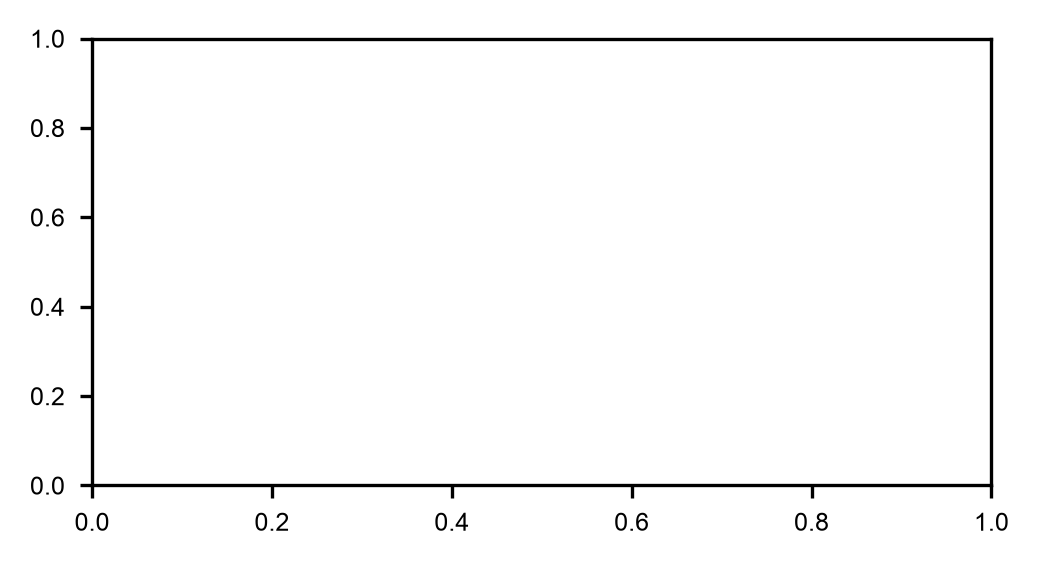

In [3]:
results_max_steepness = results_grid[:, -1, :, :, :]
real_fractions_max_steepness = real_fractions_grid[:, -1, :, :]
# flatten over dimensions 0 and 1 again
real_fractions_max_steepness = real_fractions_max_steepness.reshape(
    -1, real_fractions_max_steepness.shape[-1]
)
results_max_steepness = results_max_steepness.reshape(
    -1, results_max_steepness.shape[-2], results_max_steepness.shape[-1]
)
# remove 0s!
real_fractions_max_steepness = real_fractions_max_steepness[
    ~np.all(results_max_steepness == 0, axis=(1, 2))
]
results_max_steepness = results_max_steepness[
    ~np.all(results_max_steepness == 0, axis=(1, 2))
]
# remove where any of real fractions is less than 50
results_max_steepness = results_max_steepness[
    ~np.any(real_fractions_max_steepness < 25, axis=1)
]
real_fractions_max_steepness = real_fractions_max_steepness[
    ~np.any(real_fractions_max_steepness < 25, axis=1)
]
print(
    f"Number of rows left after removing real fractions < 50: {real_fractions_max_steepness.shape[0]}"
)

for i, metric in enumerate(stats_names):
    plt.figure(figsize=(8.5, 4.5, "cm"), layout="constrained")
    df_plot = pd.DataFrame(results_max_steepness[:, :, i], columns=method_names)
    df_plot = df_plot.melt(var_name="Method", value_name=metric)
    df_plot["Hue"] = df_plot["Method"].apply(
        lambda x: "StitchOT" if "Stitch" in x else "JointOT"
    )
    df_plot["Method"] = df_plot["Method"].replace(
        {
            "StitchOT with U": "with U",
            "JointOT with U": "with U",
            "StitchOT w/o U": "w/o U",
            "JointOT w/o U": "w/o U",
            "StitchOT w/o U \n and unsampled probs.": "unsampled probs.",
            "JointOT w/o U \n and unsampled probs.": "unsampled probs.",
            "StitchOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
            "JointOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
        }
    )
    sns.violinplot(
        data=df_plot,
        x="Method",
        y=metric,
        hue="Hue",
        palette=colors_3[:2],
        split=False,
        inner="quart",
        cut=0,
        gap=0.01,
    )  # , density_norm="width")
    # also plot a white ot with grey edge for the mean
    plt.scatter(
        x=[-0.2, 0.2, 0.8, 1.2, 1.8, 2.2, 2.8, 3.2],
        y=df_plot.groupby(["Method", "Hue"], sort=False)[metric].mean(),
        color="white",
        edgecolor="grey",
        s=6,
        zorder=10,
        linewidth=0.5,
    )
    # annotate the boxplots with the method names
    # plt.xticks(ticks=np.arange(4), labels=["with U", "w/o U", "w/o U and \n unsampled probs.", "w/o U and \n random unsampled probs."], rotation=90)
    plt.ylim(-0.02, None)
    plt.xlabel("")
    plt.yticks(ticks=np.arange(0, 1.1, 0.2))
    plt.grid(axis="y", linestyle="solid", alpha=0.4)
    plt.gca().set_axisbelow(True)
    # delete top and right spines
    plt.gca().spines["top"].set_visible(False)
    plt.gca().spines["right"].set_visible(False)
    plt.ylabel("")
    # no legend
    plt.legend([], [], frameon=False)
    plt.savefig(
        f"{figure_path}{stats_names[i].replace(' ', '_')}_all_methods_max_steepness.pdf"
    )
    plt.close()
    if metric == r"Full $\overline{\text{ACC}^{\text{R}}_{\psi}}$":
        for method_hue in df_plot.groupby(["Method", "Hue"], sort=False).groups.keys():
            method, hue = method_hue
            method_data = df_plot[
                (df_plot["Method"] == method) & (df_plot["Hue"] == hue)
            ][metric]
            median = np.median(method_data)
            mean = np.mean(method_data)
            quantiles = np.quantile(method_data, [0.05, 0.95])
            # also compute standard deviation of dataset
            sd = np.std(method_data)
            print(
                f"{hue} {method}: median={median:.4f}, mean={mean:.4f}, sd={sd:.4f}, 5% quantile={quantiles[0]:.4f}, 95% quantile={quantiles[1]:.4f}"
            )
            print("\n")

In [ ]:
df_plot.groupby(["Method", "Hue"], sort=False)[metric].mean()

Method                      Hue     
with U                      StitchOT    0.163227
                            JointOT     0.161725
w/o U                       StitchOT    0.162618
                            JointOT     0.160570
unsampled probs.            StitchOT    0.162618
                            JointOT     0.160570
random \n unsampled probs.  StitchOT    0.162618
                            JointOT     0.160570
Name: Conditional IAE, dtype: float64

In [ ]:
df_plot.groupby(["Method", "Hue"], sort=False)[metric].mean()

Method                      Hue     
with U                      StitchOT    0.163227
                            JointOT     0.161725
w/o U                       StitchOT    0.162618
                            JointOT     0.160570
unsampled probs.            StitchOT    0.162618
                            JointOT     0.160570
random \n unsampled probs.  StitchOT    0.162618
                            JointOT     0.160570
Name: Conditional IAE, dtype: float64

### Do boxplots for min steepness grid points only

In [ ]:
results_max_steepness = results_grid[:, 0, :, :, :]
real_fractions_max_steepness = real_fractions_grid[:, 0, :, :]
# flatten over dimensions 0 and 1 again
real_fractions_max_steepness = real_fractions_max_steepness.reshape(
    -1, real_fractions_max_steepness.shape[-1]
)
results_max_steepness = results_max_steepness.reshape(
    -1, results_max_steepness.shape[-2], results_max_steepness.shape[-1]
)
# remove 0s!
real_fractions_max_steepness = real_fractions_max_steepness[
    ~np.all(results_max_steepness == 0, axis=(1, 2))
]
results_max_steepness = results_max_steepness[
    ~np.all(results_max_steepness == 0, axis=(1, 2))
]
# remove where any of real fractions is less than 50
results_max_steepness = results_max_steepness[
    ~np.any(real_fractions_max_steepness < 25, axis=1)
]
real_fractions_max_steepness = real_fractions_max_steepness[
    ~np.any(real_fractions_max_steepness < 25, axis=1)
]
print(
    f"Number of rows left after removing real fractions < 50: {real_fractions_max_steepness.shape[0]}"
)


for i, metric in enumerate(stats_names):
    plt.figure(figsize=(9, 4.2, "cm"), layout="constrained")
    df_plot = pd.DataFrame(results_max_steepness[:, :, i], columns=method_names)
    df_plot = df_plot.melt(var_name="Method", value_name=metric)
    df_plot["Hue"] = df_plot["Method"].apply(
        lambda x: "StitchOT" if "Stitch" in x else "JointOT"
    )
    df_plot["Method"] = df_plot["Method"].replace(
        {
            "StitchOT with U": "with U",
            "JointOT with U": "with U",
            "StitchOT w/o U": "w/o U",
            "JointOT w/o U": "w/o U",
            "StitchOT w/o U \n and unsampled probs.": "unsampled probs.",
            "JointOT w/o U \n and unsampled probs.": "unsampled probs.",
            "StitchOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
            "JointOT w/o U \n and random unsampled probs.": "random \n unsampled probs.",
        }
    )
    sns.violinplot(
        data=df_plot,
        x="Method",
        y=metric,
        hue="Hue",
        palette=colors_3[:2],
        split=False,
        inner="quart",
        cut=0,
        gap=0.05,
    )
    plt.ylim(-0.02, None)
    plt.xlabel("")
    plt.yticks(ticks=np.arange(0, 1.1, 0.2))
    # add horizontal grid lines
    plt.grid(axis="y", linestyle="solid", alpha=0.4)
    plt.gca().set_axisbelow(True)
    plt.ylabel(stats_names[i])
    plt.savefig(
        f"{figure_path}{stats_names[i].replace(' ', '_')}_all_methods_min_steepness.pdf"
    )
    plt.close()

Number of rows left after removing real fractions < 50: 10251


In [ ]:
results_max_steepness = results_grid[:, -1, :, :, :]
real_fractions_max_steepness = real_fractions_grid[:, -1, :, :]
results_U = []
real_fractions_U = []
for U_base_rate_multiplier in range(len(grid_U_base_rate_multiplier)):
    results_max_steepness_current = results_max_steepness[
        U_base_rate_multiplier, :, :, :
    ]
    real_fractions_max_steepness_current = real_fractions_max_steepness[
        U_base_rate_multiplier, :, :
    ]
    # remove all zeros
    # get all rows where any of real_fraction values is less than 100
    valid_mask = ~np.any(real_fractions_max_steepness_current < 20, axis=1)
    results_max_steepness_current = results_max_steepness_current[valid_mask]
    real_fractions_max_steepness_current = real_fractions_max_steepness_current[
        valid_mask
    ]
    # get all rows where all of results_max_steepness_current are zero
    valid_mask = ~np.all(results_max_steepness_current == 0, axis=(1, 2))
    results_max_steepness_current = results_max_steepness_current[valid_mask]
    real_fractions_max_steepness_current = real_fractions_max_steepness_current[
        valid_mask
    ]
    # get all rows where any of results_max_steepness_current are nan
    valid_mask = ~np.any(np.isnan(results_max_steepness_current), axis=(1, 2))
    results_max_steepness_current = results_max_steepness_current[valid_mask]
    real_fractions_max_steepness_current = real_fractions_max_steepness_current[
        valid_mask
    ]
    # print how many rows
    # print(f'Number of rows left for U_base_rate_multiplier {grid_U_base_rate_multiplier[U_base_rate_multiplier]}: {results_max_steepness_current.shape[0]}')
    results_U.append(results_max_steepness_current)
    # convert real_fractions to real fractions by dividing by the sum of all fractions for each row
    real_fractions_max_steepness_current = (
        real_fractions_max_steepness_current
        / real_fractions_max_steepness_current.sum(axis=1, keepdims=True)
    )
    real_fractions_U.append(real_fractions_max_steepness_current)

for method_id in range(len(method_names)):
    plt.figure(figsize=((9, 10, "cm")))
    plt.plot(
        grid_U_base_rate_multiplier,
        [r[:, method_id, -1].mean() for r in results_U],
        label=method_names[method_id],
    )
    # same for real_fractions
    plt.plot(
        grid_U_base_rate_multiplier,
        [r[:, 4].mean() for r in real_fractions_U],
        label="Real Fractions",
    )
    # also use fill between to show the standard deviation
    plt.fill_between(
        grid_U_base_rate_multiplier,
        [r[:, method_id, -1].mean() - r[:, method_id, -1].std() for r in results_U],
        [r[:, method_id, -1].mean() + r[:, method_id, -1].std() for r in results_U],
        alpha=0.33,
    )
    plt.fill_between(
        grid_U_base_rate_multiplier,
        [r[:, 4].mean() - r[:, 4].std() for r in real_fractions_U],
        [r[:, 4].mean() + r[:, 4].std() for r in real_fractions_U],
        alpha=0.33,
    )
    plt.xlabel("U Base Rate Multiplier")
    plt.legend()
    import unicodedata
    import re

    name = (
        unicodedata.normalize("NFKD", method_names[method_id])
        .encode("ascii", "ignore")
        .decode()
    )
    safe_name = re.sub(r"\s+", "_", name)
    safe_name = re.sub(r"[^A-Za-z0-9_\-\.]", "", safe_name)
    plt.savefig(
        f"{figure_path}OT_method_{safe_name}_vs_real_fractions_U_base_rate_multiplier.pdf"
    )
    plt.close()

# do the same but now only use methods 0,2,4,6 and plot them in the same figure with colors given by colors array
plt.figure(figsize=((4.23, 4.23, "cm")), layout="constrained")
colors2 = ["black", "mediumseagreen", "salmon"]
# colors2 = ["", "", ""]
# only keep elements 0,4,6,7,8
for i, method_id in enumerate([0, 2, 4, 6]):
    if i == 3:
        color = "#b3b3b3"
    else:
        color = colors2[i]
    # compute paired difference between method and real fractions and plot difference
    print(real_fractions_U[3].shape)
    diff = [
        np.mean(np.abs(r[:, method_id, -1] - real[:, 4]))
        for r, real in zip(results_U, real_fractions_U)
    ]
    diff_sd = [
        np.std(np.abs(r[:, method_id, -1] - real[:, 4]))
        for r, real in zip(results_U, real_fractions_U)
    ]
    plt.plot(
        grid_U_base_rate_multiplier,
        [d for d in diff],
        label=method_names[method_id],
        color=color,
    )

    # also use fill between to show the standard deviation
    plt.fill_between(
        grid_U_base_rate_multiplier,
        [d - sd for d, sd in zip(diff, diff_sd)],
        [d + sd for d, sd in zip(diff, diff_sd)],
        alpha=0.2,
        color=color,
        edgecolor=color,
        linestyle=(0, (1, 1)),
        linewidth=0.7,
    )


# and ground truth
# plt.plot(grid_U_base_rate_multiplier,
#         [r[:, 4].mean() for r in real_fractions_U],
#         label='Real Fractions', color="#009E73")
# plt.fill_between(grid_U_base_rate_multiplier,
#                 [r[:, 4].mean() - r[:, 4].std() for r in real_fractions_U],
#                 [r[:, 4].mean() + r[:, 4].std() for r in real_fractions_U], alpha=0.5, color="#009E73", edgecolor=None)
# plt.plot(grid_U_base_rate_multiplier, [r[:, 4].mean() - r[:, 4].std() for r in real_fractions_U],
#         color="#009E73", linestyle='dashed', alpha=0.5)
# plt.plot(grid_U_base_rate_multiplier, [r[:, 4].mean() + r[:, 4].std() for r in real_fractions_U],
#         color="#009E73", linestyle='dashed', alpha=0.5)
# plt.legend(loc='upper left', fontsize=4.5)
# plt.xlabel('Fraction of cells expressing marker')
# plt.ylabel('Rel. transition rate to U (Inferred - Real)')
plt.ylim(-0.02, None)
plt.savefig(f"{figure_path}OT_method_all_vs_real_fractions_U_base_rate_multiplier.pdf")
plt.close()


for i, metric in enumerate(stats_names[:-3]):
    plt.figure(figsize=((4.23, 4.23, "cm")), layout="constrained")
    # colors2 = np.asarray(sns.color_palette("tab20c", n_colors=20))[[0,4,12,16]]
    # colors2 = ["#F39B7FFF", "#E64B35FF", "#DC0000FF", "#b3b3b3" ]
    # colors2 = ["#F39B7F99","#E64B35FF", "#91D1C2FF"]
    # colors2 = ["#3C5488FF", "#F39B7FFF", ""]
    # colors2 = np.asarray(sns.color_palette("Reds", n_colors=3))
    # only keep elements 0,4,6,7,8
    for j, method_id in enumerate([0, 2, 4, 6]):
        if j == 3:
            color = "#b3b3b3"
        else:
            color = colors2[j]
        plt.plot(
            grid_U_base_rate_multiplier,
            [r[:, method_id, i].mean() for r in results_U],
            label=method_names[method_id],
            color=color,
        )
        plt.fill_between(
            grid_U_base_rate_multiplier,
            [r[:, method_id, i].mean() - r[:, method_id, i].std() for r in results_U],
            [r[:, method_id, i].mean() + r[:, method_id, i].std() for r in results_U],
            alpha=0.2,
            color=color,
            edgecolor=color,
            linestyle=(0, (1, 1)),
            linewidth=0.7,
        )
        plt.ylim(-0.02, 1.0)
    # plt.legend(loc='upper right', fontsize=4.5)
    # plt.xlabel('Fraction of cells expressing marker')
    # plt.ylabel(stats_names[i])
    plt.savefig(
        f"{figure_path}OT_method_all_vs_U_fracs_{stats_names[i].replace(' ', '_')}.pdf"
    )
    plt.close()

(334, 5)
(334, 5)
(334, 5)
(334, 5)


In [ ]:
# Do a heatmap over the grid of U_base_rate_multiplier and U_steepness, where the value is the mean of the full IAE metric
import re
import unicodedata

full_iae_heatmaps = np.full(
    (len(method_names), len(grid_U_steepness), len(grid_U_base_rate_multiplier)),
    np.nan,
)

for steepness_idx in range(len(grid_U_steepness)):
    for base_idx in range(len(grid_U_base_rate_multiplier)):
        results_cell = results_grid[base_idx, steepness_idx, :, :, :]
        real_fractions_cell = real_fractions_grid[base_idx, steepness_idx, :, :]
        valid_mask = ~np.any(real_fractions_cell < 25, axis=1)
        results_cell = results_cell[valid_mask]
        real_fractions_cell = real_fractions_cell[valid_mask]
        valid_mask = ~np.all(results_cell == 0, axis=(1, 2))
        results_cell = results_cell[valid_mask]
        real_fractions_cell = real_fractions_cell[valid_mask]
        valid_mask = ~np.any(np.isnan(results_cell), axis=(1, 2))
        results_cell = results_cell[valid_mask]
        if results_cell.shape[0] == 0:
            continue
        full_iae_heatmaps[:, steepness_idx, base_idx] = results_cell[:, :, 2].mean(
            axis=0
        )

vmax = np.nanmax(full_iae_heatmaps)
for method_id, method_name in enumerate(method_names):
    plt.figure(figsize=(3.3 * cm, 3.3 * cm), layout="constrained")
    ax = sns.heatmap(
        full_iae_heatmaps[method_id, ::-1, ::-1],
        cmap="viridis",
        vmin=0.0,
        vmax=1.0,
        xticklabels=5,
        yticklabels=5,
        rasterized=True,
    )
    # ax.set_ylabel('Fraction of cells expressing marker')
    # ax.set_xlabel('Steepness (log10)')
    ax.set_xticks(
        ticks=[0.5, 5.5, 10.5, 15.5, 19.5],
        labels=["1.0", "0.75", "0.5", "0.25", "0.0"][::-1],
    )
    ax.set_yticks(
        ticks=np.arange(10)[::3] + 0.5,
        labels=[f"{x:.1f}" for x in np.log10(grid_U_steepness[::-3])],
    )
    # ax.set_yticks(ticks=np.arange(len(grid_U_steepness))[::1]+0.5,  labels=grid_U_steepness[::1])
    # ax.tick_params(axis='x', rotation=45)
    # ax.tick_params(axis='y', rotation=0)
    # dont show the colorbar
    ax.collections[0].colorbar.remove()

    safe_name = (
        unicodedata.normalize("NFKD", method_name).encode("ascii", "ignore").decode()
    )
    safe_name = re.sub(r"\s+", "_", safe_name)
    safe_name = re.sub(r"[^A-Za-z0-9_\-\.]", "", safe_name)
    plt.savefig(f"{figure_path}full_ACC_heatmap_{safe_name}.pdf", dpi=500)
    plt.close()

plt.figure(figsize=(1.5 * cm, 3 * cm), layout="constrained")
norm = plt.Normalize(vmin=0.0, vmax=1.0)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
plt.colorbar(sm, cax=plt.gca(), orientation="vertical")
# make colorbar less wide
plt.gca().set_position([0.05, 0.05, 0.1, 0.6])
plt.savefig(f"{figure_path}full_ACC_heatmap_colorbar.pdf")
plt.close()